<a href="https://colab.research.google.com/github/Themostamazing-bot/Friedman-numerical-implementation/blob/main/tsotetsi_code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Friedmann Project — Numerical Implementation
**Tsotetsi Lehlohonolo | Student Number: 4351164**  
**Third-Year Research Project | Physics and Astronomy**

Run each cell in order. All figures are saved to a `figures/` folder automatically.

## Cell 1 — Imports and Constants

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp, quad
from scipy.special import hyp2f1
import matplotlib.pyplot as plt
import os

os.makedirs('figures', exist_ok=True)
plt.rcParams.update({'font.size': 11, 'axes.grid': True, 'grid.alpha': 0.3, 'figure.dpi': 150})

# Cosmological constants
H0_kms = 67.4               # Hubble constant [km/s/Mpc]
H0_Gyr = H0_kms / 977.792  # H0 in [Gyr^-1]
c_kms  = 2.998e5            # Speed of light [km/s]

# Fiducial flat LCDM parameters (Planck 2018)
OM0 = 0.30
OL0 = 0.70

print(f'H0 = {H0_kms} km/s/Mpc  =  {H0_Gyr:.5f} Gyr^-1')
print(f'1/H0 = {1/H0_Gyr:.2f} Gyr')

H0 = 67.4 km/s/Mpc  =  0.06893 Gyr^-1
1/H0 = 14.51 Gyr


## Cell 2 — Dimensionless Hubble Function E²(a) and E²(z)

In [ ]:
def E2_a(a, Om, OL, Or=0.0):
    """E^2(a) = H^2(a)/H0^2 as a function of scale factor."""
    return Or*a**(-4) + Om*a**(-3) + OL

def E2_z(z, Om, OL, Or=0.0):
    """E^2(z) = H^2(z)/H0^2 as a function of redshift."""
    return Or*(1+z)**4 + Om*(1+z)**3 + OL

## Cell 3 — ODE Solver: da/dt = H0 · a · E(a)

In [ ]:
def rhs(t, y, Om, OL, Or=0.0):
    """Right-hand side of IVP: da/dt = H0 * a * sqrt(E2(a))."""
    a = y[0]
    if a <= 0:
        return [1e-30]
    val = E2_a(a, Om, OL, Or)
    if val <= 0:
        return [0.0]
    return [H0_Gyr * a * np.sqrt(val)]

def solve_cosmology(Om, OL, Or=0.0, t_max=25.0):
    """Solve a(t) from early times to t_max [Gyr]."""
    a0 = 1e-4
    if Or > 0:
        t_start = a0**2 / (2 * H0_Gyr * np.sqrt(Or))
    elif Om > 0:
        t_start = (2/3) * a0**(3/2) / (H0_Gyr * np.sqrt(Om))
    else:
        t_start = 1e-3  # de Sitter: no Big Bang
    sol = solve_ivp(rhs, [t_start, t_max], [a0],
                    args=(Om, OL, Or),
                    method='DOP853',
                    rtol=1e-10, atol=1e-12,
                    max_step=0.05, dense_output=True)
    return sol

def find_t0(Om, OL, Or=0.0):
    """Present age of universe in Gyr (time when a = 1)."""
    sol = solve_cosmology(Om, OL, Or, t_max=25.0)
    a_arr, t_arr = sol.y[0], sol.t
    if a_arr.max() < 1.0:
        return None
    idx = np.searchsorted(a_arr, 1.0)
    if idx == 0:
        return t_arr[0]
    t1, t2 = t_arr[idx-1], t_arr[idx]
    a1, a2 = a_arr[idx-1], a_arr[idx]
    return t1 + (1.0 - a1)*(t2 - t1)/(a2 - a1)

## Cell 4 — Analytic Solutions and Key Predicted Values

In [ ]:
def a_matter_analytic(t, Om=1.0):
    """Matter-only: a(t) = (3/2 H0 sqrt(Om) t)^{2/3}"""
    return (1.5 * H0_Gyr * np.sqrt(Om) * np.asarray(t))**(2/3)

def a_radiation_analytic(t, Or=1.0):
    """Radiation-only: a(t) = (2 H0 sqrt(Or) t)^{1/2}"""
    return (2.0 * H0_Gyr * np.sqrt(Or) * np.asarray(t))**0.5

def a_LCDM_analytic(t, Om=OM0, OL=OL0):
    """Full flat LCDM: a(t) = (Om/OL)^{1/3} sinh^{2/3}(3/2 sqrt(OL) H0 t)"""
    arg = 1.5 * np.sqrt(OL) * H0_Gyr * np.asarray(t)
    return (Om/OL)**(1/3) * np.sinh(arg)**(2/3)

def t0_LCDM_analytic(Om, OL):
    """Analytic age of flat LCDM universe [Gyr]."""
    return (2.0 / (3.0 * H0_Gyr * np.sqrt(OL))) * np.log((1+np.sqrt(OL))/np.sqrt(Om))

def t0_matter_analytic(Om=1.0):
    """Analytic age of matter-only universe [Gyr]."""
    return 2.0 / (3.0 * H0_Gyr * np.sqrt(Om))

# Print key predicted values
t0_lcdm  = t0_LCDM_analytic(OM0, OL0)
t0_mat   = t0_matter_analytic()
q0_val   = OM0/2 - OL0
j0_val   = 1.0
s0_val   = 1.0 - 4.5*OM0
zacc_val = (2*OL0/OM0)**(1/3) - 1

print('--- Key cosmological parameters (Om0=0.3, OL0=0.7) ---')
print(f'  q0        = {q0_val:.4f}   [predicted: -0.55]')
print(f'  j0        = {j0_val:.4f}   [predicted:  1.00]')
print(f'  s0        = {s0_val:.4f}')
print(f'  z_acc     = {zacc_val:.4f}   [predicted:  0.67]')
print(f'  t0 (LCDM) = {t0_lcdm:.3f} Gyr  [predicted: 14.0 Gyr]')
print(f'  t0 (matter-only) = {t0_mat:.3f} Gyr  [predicted: 9.7 Gyr]')

--- Key cosmological parameters (Om0=0.3, OL0=0.7) ---
  q0        = -0.5500   [predicted: -0.55]
  j0        = 1.0000   [predicted:  1.00]
  s0        = -0.3500
  z_acc     = 0.6711   [predicted:  0.67]
  t0 (LCDM) = 13.986 Gyr  [predicted: 14.0 Gyr]
  t0 (matter-only) = 9.672 Gyr  [predicted: 9.7 Gyr]


## Cell 5 — Cosmological Distances

In [ ]:
def chi(z, Om, OL, Or=0.0):
    """Comoving distance chi(z) [Mpc]."""
    integrand = lambda zp: 1.0 / np.sqrt(E2_z(zp, Om, OL, Or))
    result, _ = quad(integrand, 0, z, limit=300)
    return (c_kms / H0_kms) * result

def dL(z, Om, OL, Or=0.0):
    """Luminosity distance dL(z) [Mpc]."""
    return (1+z) * chi(z, Om, OL, Or)

def dA(z, Om, OL, Or=0.0):
    """Angular diameter distance dA(z) [Mpc]."""
    return chi(z, Om, OL, Or) / (1+z)

def mu(z, Om, OL, Or=0.0):
    """Distance modulus mu(z)."""
    return 5 * np.log10(dL(z, Om, OL, Or) * 1e6 / 10.0)

def dL_taylor(z, Om, OL):
    """Cosmographic Taylor expansion of dL to O(z^2)."""
    q = Om/2 - OL
    j = 1.0   # j0 = 1 identically for flat LCDM
    z = np.asarray(z)
    return (c_kms/H0_kms) * z * (1 + (1-q)/2*z - (1-q-3*q**2+j)/6*z**2)

# Vectorised versions for array inputs
chi_v = np.vectorize(chi)
dL_v  = np.vectorize(dL)
mu_v  = np.vectorize(mu)

## Cell 6 — Cosmographic Parameters

In [ ]:
def q0(Om, OL):
    """Deceleration parameter."""
    return Om/2 - OL

def j0_flat(Om, OL):
    """Jerk parameter for flat LCDM — always 1."""
    return 1.0

def s0_flat(Om, OL):
    """Snap parameter for flat LCDM."""
    return 1.0 - 4.5*Om

def z_acc(Om, OL):
    """Redshift of transition from deceleration to acceleration."""
    return (2*OL/Om)**(1/3) - 1

print(f'q0      = {q0(OM0, OL0):.4f}')
print(f'j0      = {j0_flat(OM0, OL0):.4f}')
print(f's0      = {s0_flat(OM0, OL0):.4f}')
print(f'z_acc   = {z_acc(OM0, OL0):.4f}')

q0      = -0.5500
j0      = 1.0000
s0      = -0.3500
z_acc   = 0.6711


## Cell 7 — Figure 1: Expansion Histories a(t) with Analytic Overlays

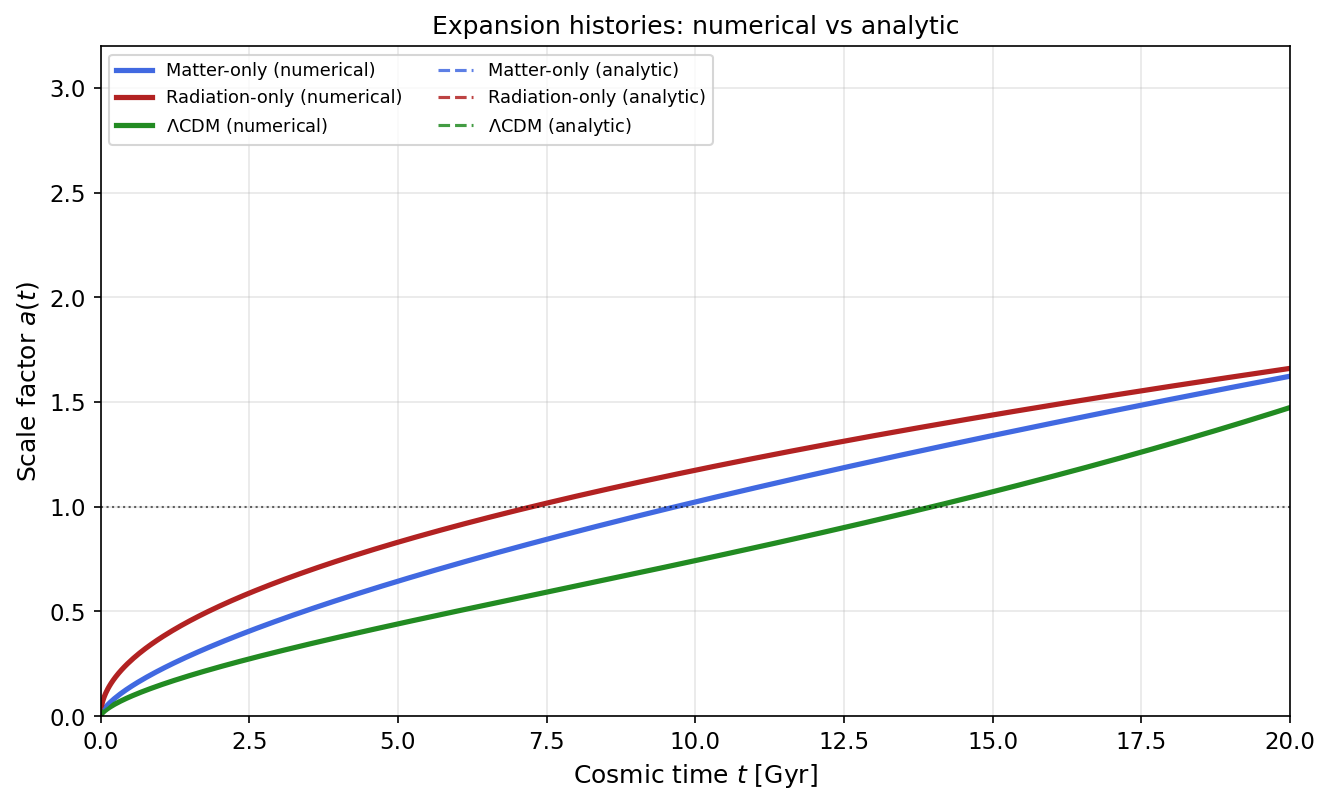

Figure 1 saved.


In [ ]:
fig, ax = plt.subplots(figsize=(9, 5.5))
t_an = np.linspace(0.05, 20, 2000)

# Numerical solutions
for Om, OL, Or, col, lbl in [
        (1.0, 0.0, 0.0, 'royalblue',   'Matter-only'),
        (0.0, 0.0, 1.0, 'firebrick',   'Radiation-only'),
        (OM0, OL0, 0.0, 'forestgreen', r'$\Lambda$CDM')]:
    sol = solve_cosmology(Om, OL, Or, t_max=20)
    ax.plot(sol.t, sol.y[0], color=col, lw=2.5, label=f'{lbl} (numerical)')

# Analytic overlays
ax.plot(t_an, a_matter_analytic(t_an),    color='royalblue',   lw=1.5, ls='--', alpha=0.85, label='Matter-only (analytic)')
ax.plot(t_an, a_radiation_analytic(t_an), color='firebrick',   lw=1.5, ls='--', alpha=0.85, label='Radiation-only (analytic)')
ax.plot(t_an, a_LCDM_analytic(t_an),      color='forestgreen', lw=1.5, ls='--', alpha=0.85, label=r'$\Lambda$CDM (analytic)')

ax.axhline(1.0, color='k', ls=':', lw=1, alpha=0.6)
ax.set_xlabel('Cosmic time $t$ [Gyr]', fontsize=12)
ax.set_ylabel('Scale factor $a(t)$', fontsize=12)
ax.set_title('Expansion histories: numerical vs analytic', fontsize=12)
ax.set_xlim(0, 20); ax.set_ylim(0, 3.2)
ax.legend(fontsize=8.5, loc='upper left', ncol=2)
plt.tight_layout()
plt.savefig('figures/fig1_expansion_histories.pdf', bbox_inches='tight')
plt.savefig('figures/fig1_expansion_histories.png', dpi=200, bbox_inches='tight')
plt.show()
print('Figure 1 saved.')

## Cell 8 — Figure 2: H(z) vs Redshift

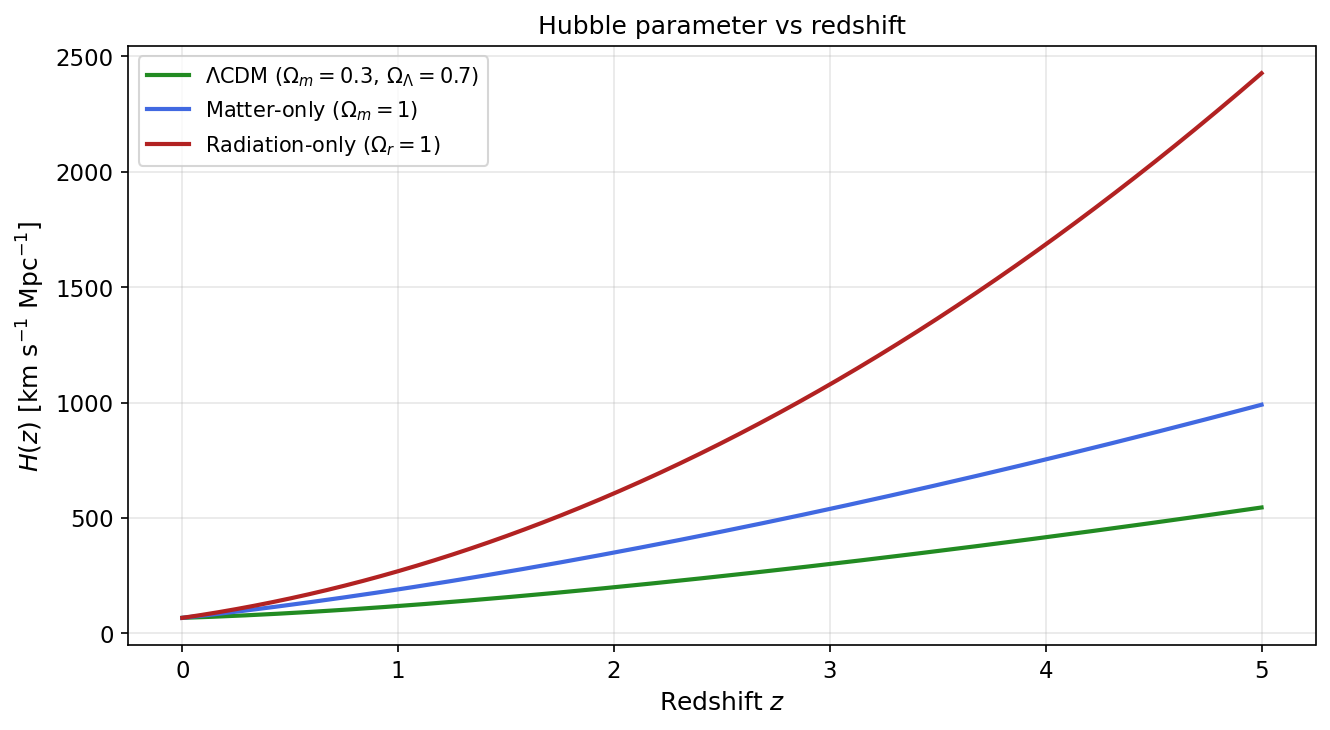

Figure 2 saved.


In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
z_arr = np.linspace(0, 5, 600)

for Om, OL, Or, col, lbl in [
        (OM0, OL0, 0.0, 'forestgreen', r'$\Lambda$CDM ($\Omega_m=0.3,\,\Omega_\Lambda=0.7$)'),
        (1.0, 0.0, 0.0, 'royalblue',   r'Matter-only ($\Omega_m=1$)'),
        (0.0, 0.0, 1.0, 'firebrick',   r'Radiation-only ($\Omega_r=1$)')]:
    H_arr = H0_kms * np.sqrt(E2_z(z_arr, Om, OL, Or))
    ax.plot(z_arr, H_arr, color=col, lw=2, label=lbl)

ax.set_xlabel('Redshift $z$', fontsize=12)
ax.set_ylabel(r'$H(z)$ [km s$^{-1}$ Mpc$^{-1}$]', fontsize=12)
ax.set_title('Hubble parameter vs redshift', fontsize=12)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('figures/fig2_hubble.pdf', bbox_inches='tight')
plt.savefig('figures/fig2_hubble.png', dpi=200, bbox_inches='tight')
plt.show()
print('Figure 2 saved.')

## Cell 9 — Figure 3: Distance Modulus μ(z)

<>:11: SyntaxWarning: invalid escape sequence '\m'
<>:11: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_776/1775845769.py:11: SyntaxWarning: invalid escape sequence '\m'
  ax.set_ylabel('Distance modulus $\mu$', fontsize=12)


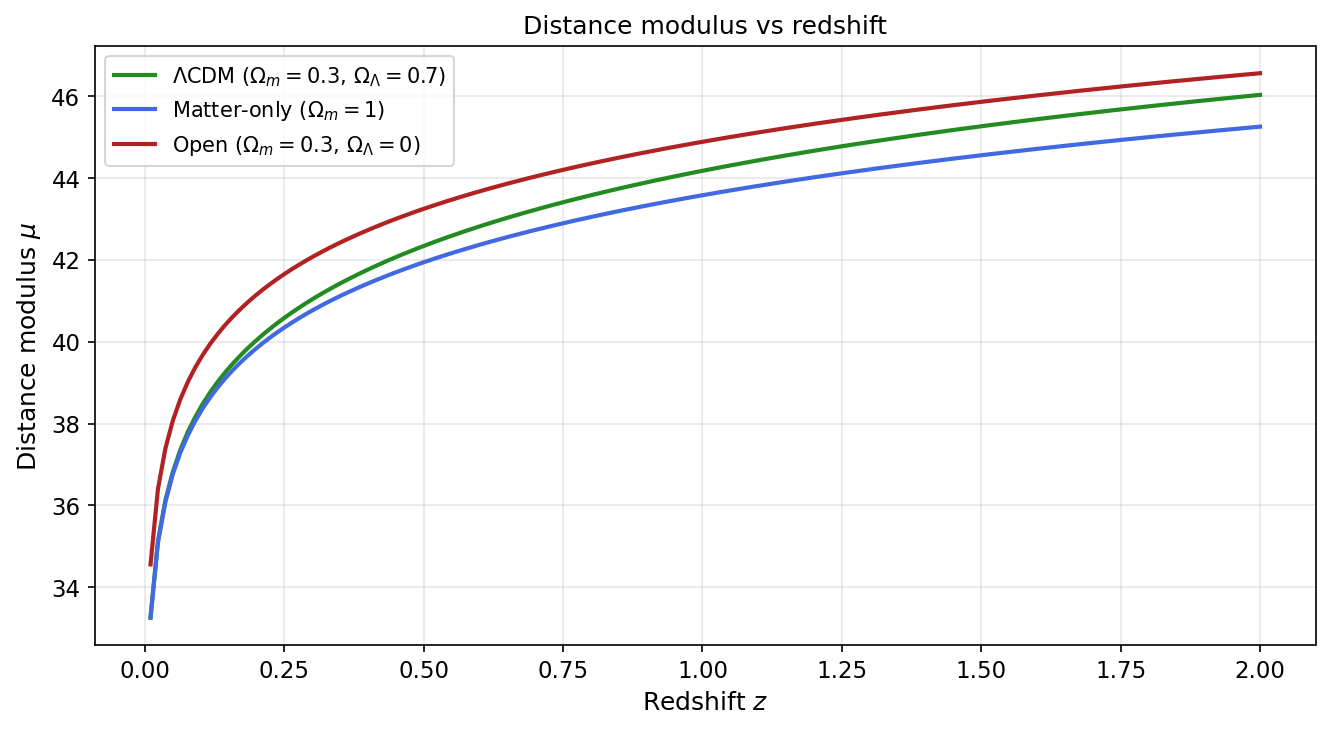

Figure 3 saved.


In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
z_mu = np.linspace(0.01, 2.0, 150)

for Om, OL, col, lbl in [
        (0.3, 0.7, 'forestgreen', r'$\Lambda$CDM ($\Omega_m=0.3,\,\Omega_\Lambda=0.7$)'),
        (1.0, 0.0, 'royalblue',   r'Matter-only ($\Omega_m=1$)'),
        (0.3, 0.0, 'firebrick',   r'Open ($\Omega_m=0.3,\,\Omega_\Lambda=0$)')]:
    ax.plot(z_mu, mu_v(z_mu, Om, OL), color=col, lw=2, label=lbl)

ax.set_xlabel('Redshift $z$', fontsize=12)
ax.set_ylabel('Distance modulus $\mu$', fontsize=12)
ax.set_title('Distance modulus vs redshift', fontsize=12)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('figures/fig3_distance_modulus.pdf', bbox_inches='tight')
plt.savefig('figures/fig3_distance_modulus.png', dpi=200, bbox_inches='tight')
plt.show()
print('Figure 3 saved.')

## Cell 10 — Figures 4–7: Parameter Sweep over Ω_m0

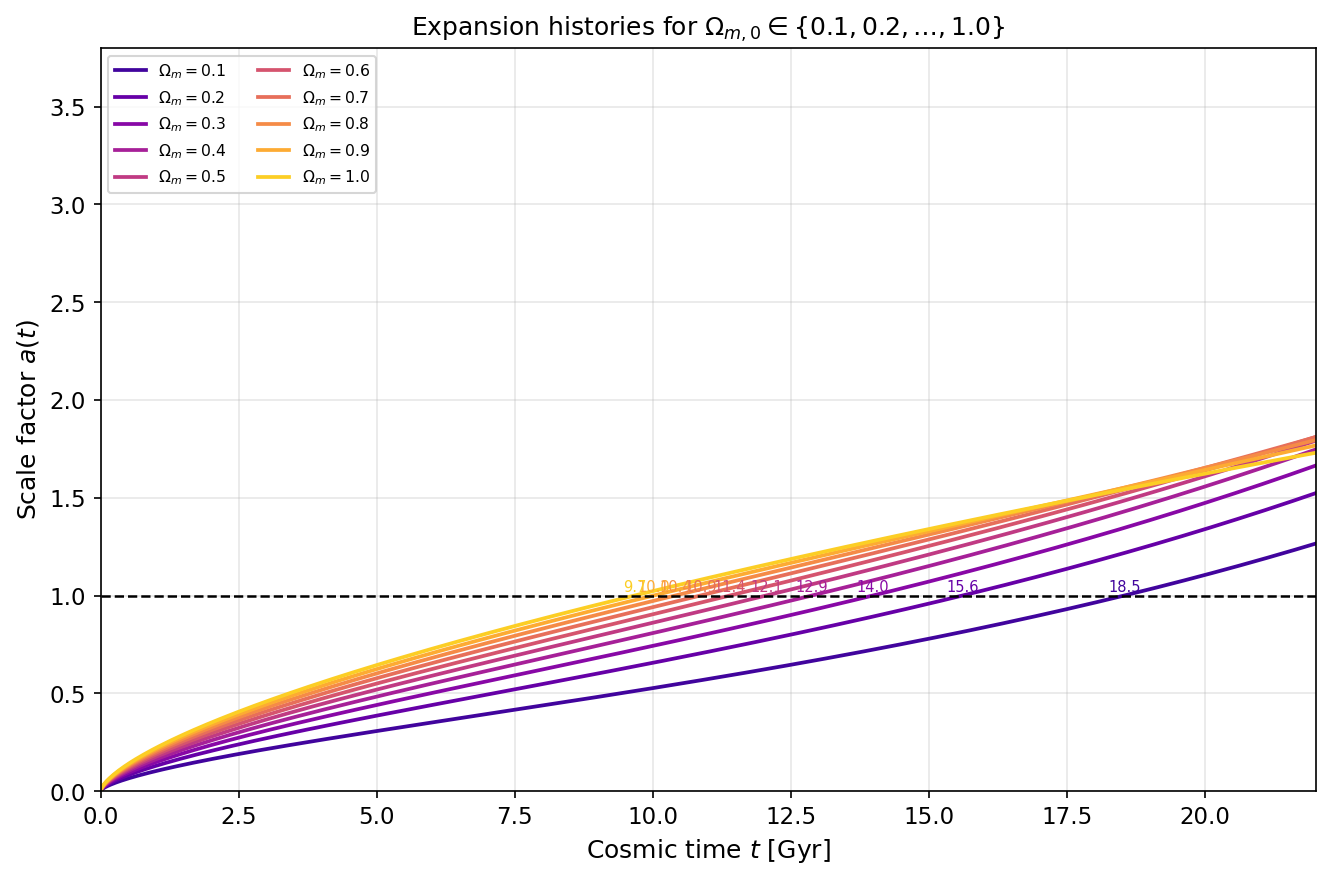

Figure 4 saved.


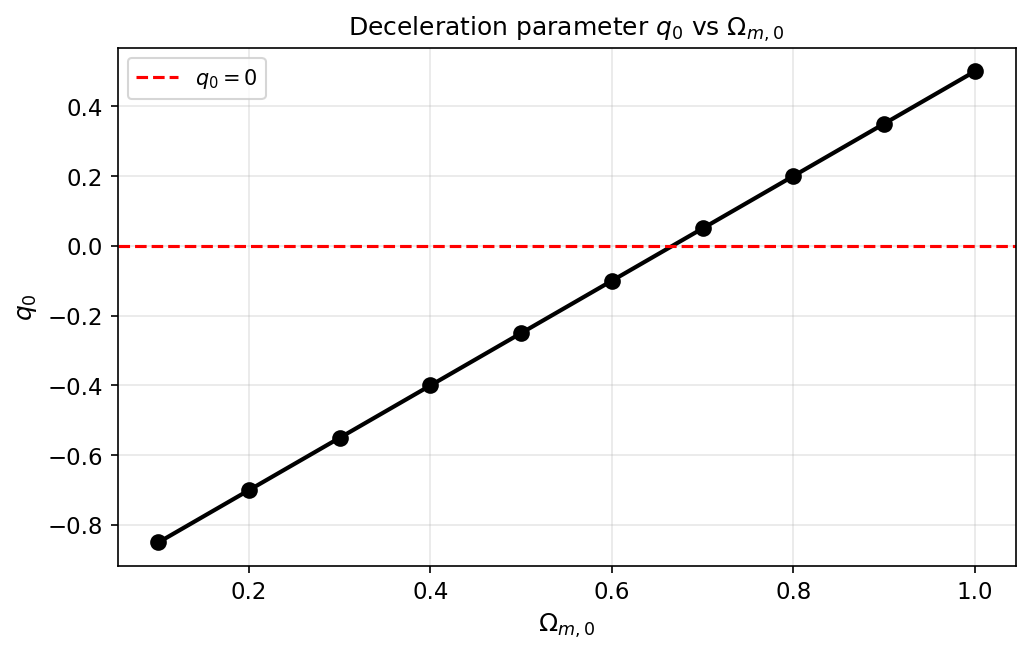

Figure 5 saved.


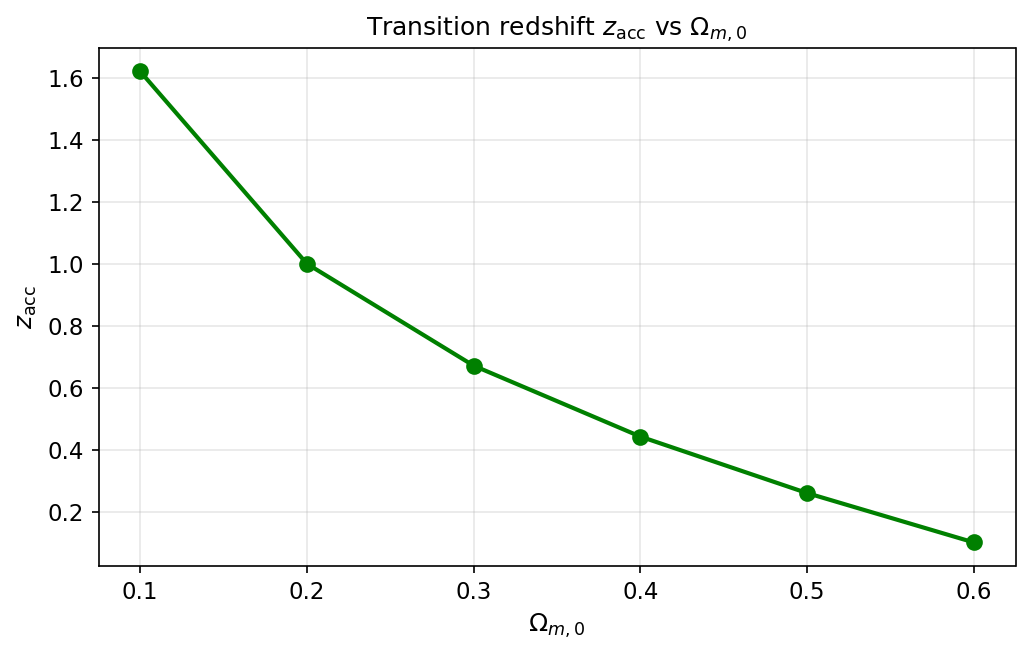

Figure 6 saved.


/tmp/ipykernel_776/1649921858.py:16: RuntimeWarning: divide by zero encountered in scalar divide
  return (2.0 / (3.0 * H0_Gyr * np.sqrt(OL))) * np.log((1+np.sqrt(OL))/np.sqrt(Om))
/tmp/ipykernel_776/1649921858.py:16: RuntimeWarning: invalid value encountered in scalar multiply
  return (2.0 / (3.0 * H0_Gyr * np.sqrt(OL))) * np.log((1+np.sqrt(OL))/np.sqrt(Om))


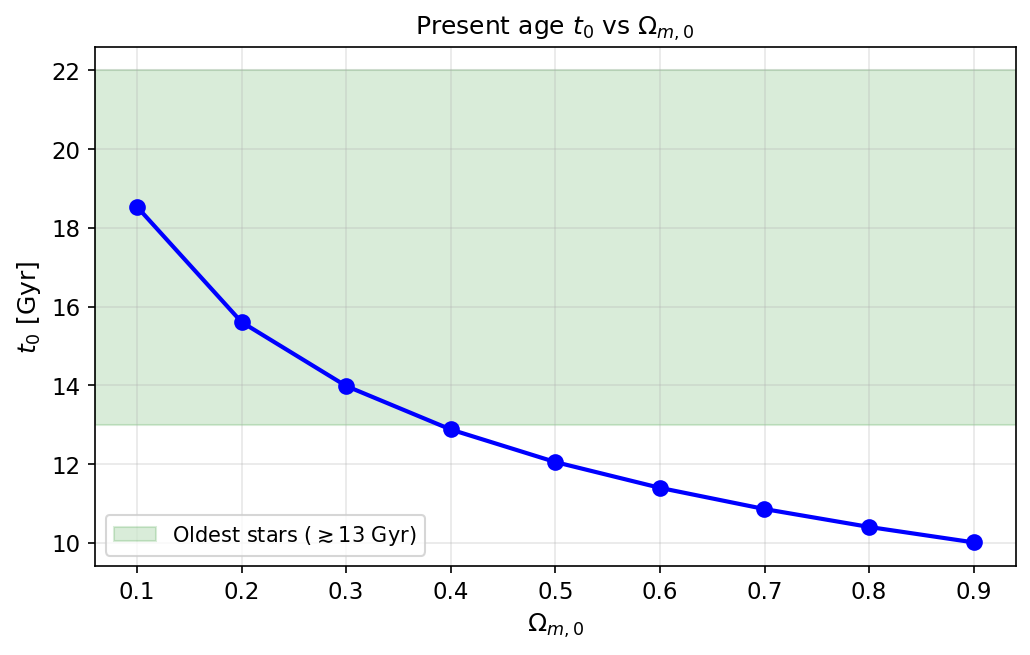

Figure 7 saved.


In [ ]:
Om0_sweep = np.round(np.arange(0.1, 1.05, 0.1), 1)
cmap      = plt.cm.plasma(np.linspace(0.1, 0.9, len(Om0_sweep)))

# --- Figure 4: all a(t) expansion histories ---
fig, ax = plt.subplots(figsize=(9, 6))
for i, Om in enumerate(Om0_sweep):
    OL   = round(1 - Om, 10)
    sol  = solve_cosmology(Om, OL, t_max=25)
    t0_v = find_t0(Om, OL)
    ax.plot(sol.t, sol.y[0], color=cmap[i], lw=1.8, label=f'$\\Omega_m={Om:.1f}$')
    if t0_v:
        ax.annotate(f'{t0_v:.1f}', xy=(t0_v, 1.02), fontsize=7, color=cmap[i], ha='center')

ax.axhline(1.0, color='k', ls='--', lw=1.2)
ax.set_xlabel('Cosmic time $t$ [Gyr]', fontsize=12)
ax.set_ylabel('Scale factor $a(t)$', fontsize=12)
ax.set_title(r'Expansion histories for $\Omega_{m,0}\in\{0.1,0.2,\ldots,1.0\}$', fontsize=12)
ax.set_xlim(0, 22); ax.set_ylim(0, 3.8)
ax.legend(fontsize=7.5, loc='upper left', ncol=2)
plt.tight_layout()
plt.savefig('figures/fig4_sweep_at.pdf', bbox_inches='tight')
plt.savefig('figures/fig4_sweep_at.png', dpi=200, bbox_inches='tight')
plt.show()
print('Figure 4 saved.')

# --- Figure 5: q0 vs Om0 ---
q0_arr = Om0_sweep/2 - (1 - Om0_sweep)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(Om0_sweep, q0_arr, 'ko-', lw=2, ms=7)
ax.axhline(0, color='r', ls='--', lw=1.5, label='$q_0=0$')
ax.set_xlabel(r'$\Omega_{m,0}$', fontsize=12)
ax.set_ylabel(r'$q_0$', fontsize=12)
ax.set_title(r'Deceleration parameter $q_0$ vs $\Omega_{m,0}$', fontsize=12)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('figures/fig5_q0_sweep.pdf', bbox_inches='tight')
plt.savefig('figures/fig5_q0_sweep.png', dpi=200, bbox_inches='tight')
plt.show()
print('Figure 5 saved.')

# --- Figure 6: z_acc vs Om0 (only accelerating models) ---
Om_acc   = Om0_sweep[Om0_sweep < 2/3]
zacc_arr = (2*(1-Om_acc)/Om_acc)**(1/3) - 1
fig, ax  = plt.subplots(figsize=(7, 4.5))
ax.plot(Om_acc, zacc_arr, 'go-', lw=2, ms=7)
ax.set_xlabel(r'$\Omega_{m,0}$', fontsize=12)
ax.set_ylabel(r'$z_\mathrm{acc}$', fontsize=12)
ax.set_title(r'Transition redshift $z_\mathrm{acc}$ vs $\Omega_{m,0}$', fontsize=12)
plt.tight_layout()
plt.savefig('figures/fig6_zacc_sweep.pdf', bbox_inches='tight')
plt.savefig('figures/fig6_zacc_sweep.png', dpi=200, bbox_inches='tight')
plt.show()
print('Figure 6 saved.')

# --- Figure 7: t0 vs Om0 ---
t0_arr = np.array([t0_LCDM_analytic(Om, 1-Om) for Om in Om0_sweep])
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(Om0_sweep, t0_arr, 'bo-', lw=2, ms=7)
ax.axhspan(13, 22, alpha=0.15, color='green', label='Oldest stars ($\\gtrsim13$ Gyr)')
ax.set_xlabel(r'$\Omega_{m,0}$', fontsize=12)
ax.set_ylabel(r'$t_0$ [Gyr]', fontsize=12)
ax.set_title(r'Present age $t_0$ vs $\Omega_{m,0}$', fontsize=12)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('figures/fig7_t0_sweep.pdf', bbox_inches='tight')
plt.savefig('figures/fig7_t0_sweep.png', dpi=200, bbox_inches='tight')
plt.show()
print('Figure 7 saved.')

## Cell 11 — Figure 8: Cosmographic Check d_L(z)

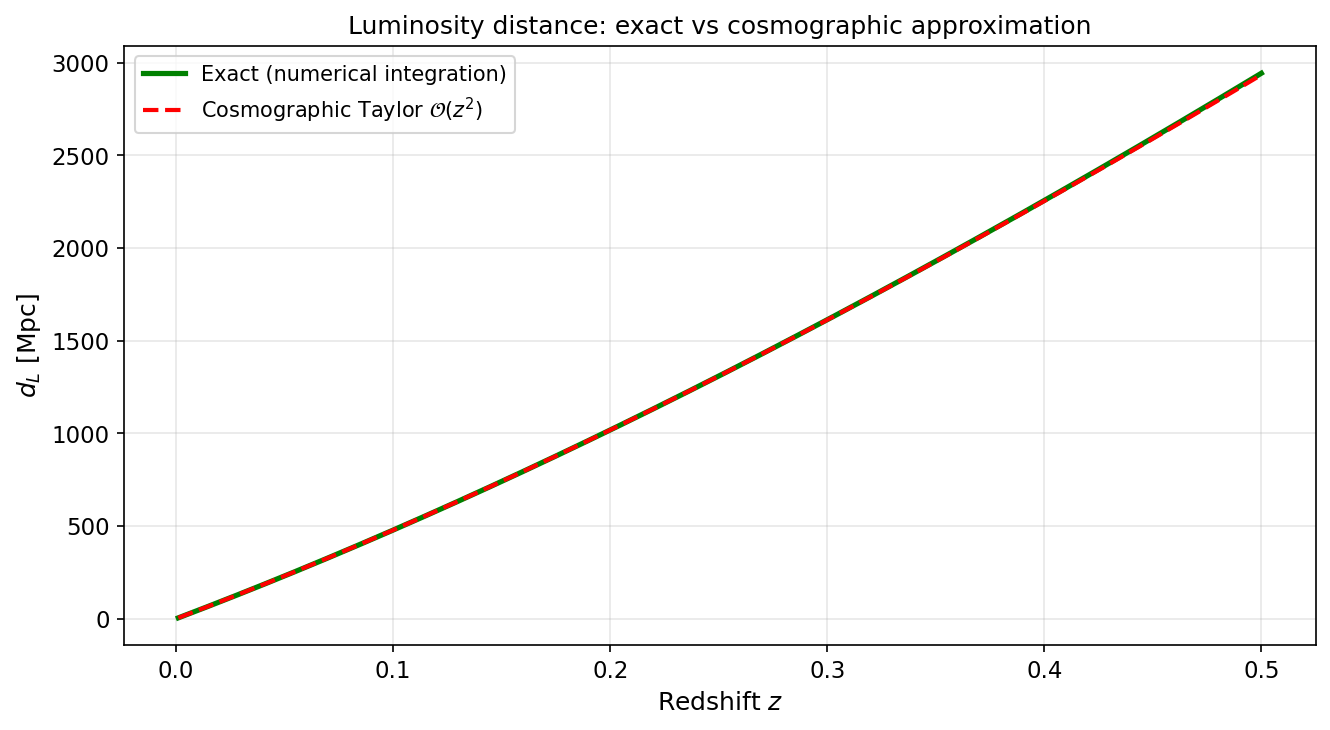

Figure 8 saved.


In [ ]:
z_cg  = np.linspace(0.001, 0.5, 300)
dL_ex = dL_v(z_cg, OM0, OL0)
dL_ty = dL_taylor(z_cg, OM0, OL0)
err   = np.abs(dL_ty - dL_ex) / dL_ex * 100

idx_break = np.argmax(err > 1.0)
z_break   = z_cg[idx_break] if idx_break > 0 else None

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(z_cg, dL_ex, 'g-',  lw=2.5, label='Exact (numerical integration)')
ax.plot(z_cg, dL_ty, 'r--', lw=2,   label=r'Cosmographic Taylor $\mathcal{O}(z^2)$')
if z_break:
    ax.axvline(z_break, color='gray', ls=':', lw=1.5,
               label=f'1% deviation at $z\\approx{z_break:.2f}$')
    print(f'Cosmographic Taylor breaks down (>1%) at z = {z_break:.3f}')
ax.set_xlabel('Redshift $z$', fontsize=12)
ax.set_ylabel('$d_L$ [Mpc]', fontsize=12)
ax.set_title('Luminosity distance: exact vs cosmographic approximation', fontsize=12)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('figures/fig8_cosmo_check.pdf', bbox_inches='tight')
plt.savefig('figures/fig8_cosmo_check.png', dpi=200, bbox_inches='tight')
plt.show()
print('Figure 8 saved.')

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## Cell 12 — Figure 9: Numerical Precision Check |C(t)|

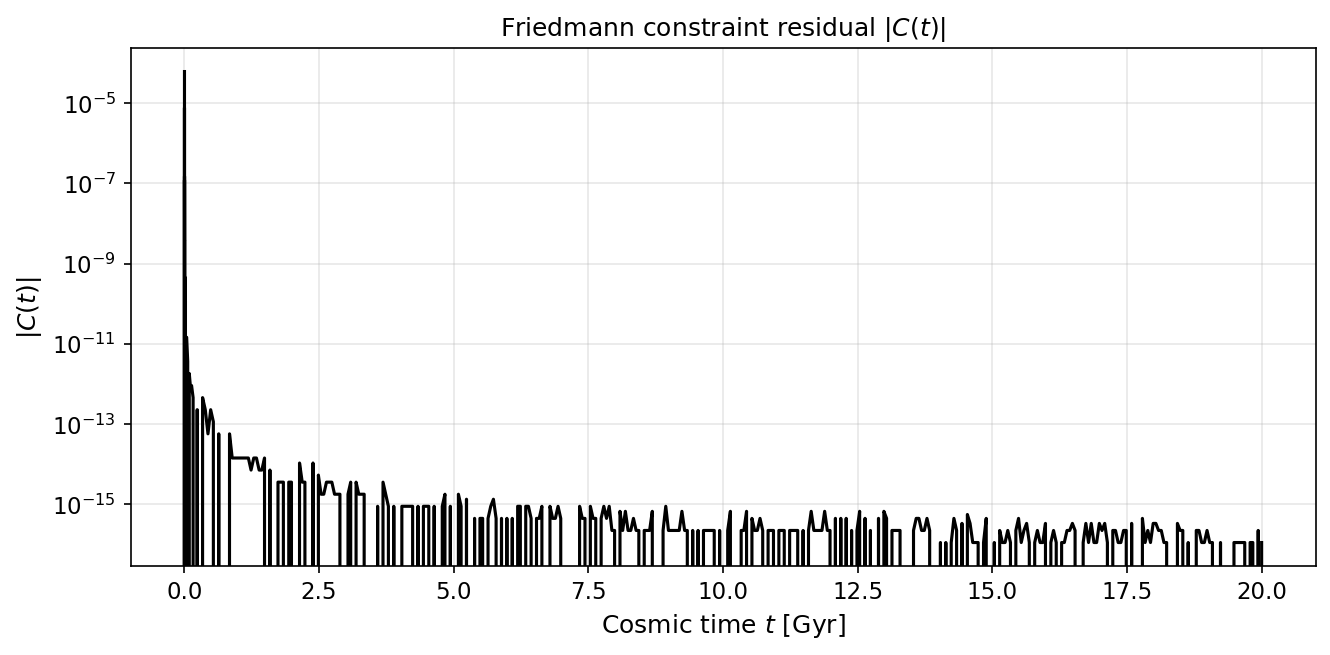

Figure 9 saved.

All figures saved to figures/


In [ ]:
sol_p  = solve_cosmology(OM0, OL0, t_max=20)
a_p    = sol_p.y[0]
t_p    = sol_p.t

# Compute adot from RHS, then H = adot/a, then E2 = (H/H0)^2
adot_p = np.array([rhs(t_p[i], [a_p[i]], OM0, OL0)[0] for i in range(len(t_p))])
H_p    = adot_p / a_p
E2_num = (H_p / H0_Gyr)**2
E2_th  = E2_a(a_p, OM0, OL0)
C_t    = np.abs(E2_num - E2_th)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.semilogy(t_p, C_t, 'k-', lw=1.5)
ax.set_xlabel('Cosmic time $t$ [Gyr]', fontsize=12)
ax.set_ylabel(r'$|C(t)|$', fontsize=12)
ax.set_title('Friedmann constraint residual $|C(t)|$', fontsize=12)
plt.tight_layout()
plt.savefig('figures/fig9_precision.pdf', bbox_inches='tight')
plt.savefig('figures/fig9_precision.png', dpi=200, bbox_inches='tight')
plt.show()
print('Figure 9 saved.')
print('\nAll figures saved to figures/')